In [26]:
import pandas as pd
import numpy as np

import re
import time

from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import requests
from scipy import stats
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", None)

In [27]:
countries = [
    {"country": "United States",      "iso3": "USA"},
    {"country": "China",              "iso3": "CHN"},
    {"country": "Germany",            "iso3": "DEU"},
    {"country": "Japan",              "iso3": "JPN"},
    {"country": "United Kingdom",     "iso3": "GBR"},
    {"country": "France",             "iso3": "FRA"},
    {"country": "Russian Federation", "iso3": "RUS"},
    {"country": "Australia",          "iso3": "AUS"},
    {"country": "Kazakhstan",         "iso3": "KAZ"},
    {"country": "Norway",             "iso3": "NOR"},
    {"country": "Kenya",              "iso3": "KEN"},
    {"country": "Jamaica",            "iso3": "JAM"},
]
len(countries)

12

In [28]:
def fetch_indicator(iso3, indicator):
    url = f"https://api.worldbank.org/v2/country/{iso3}/indicator/{indicator}"
    params = {"format": "json", "mrnev": 1}
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    payload = response.json()

    records = payload[1] #payload[0] is metadata
    record = records[0]
    return record["date"], record["value"]

def fetch_economy(country, iso3):
    gdp_year, gdp = fetch_indicator(iso3, "NY.GDP.MKTP.CD")
    pop_year, pop = fetch_indicator(iso3, "SP.POP.TOTL")
    return {
        "country": country,
        "iso3": iso3,
        "gdp_current_usd": gdp,
        "gdp_year": gdp_year,
        "population": pop,
        "population_year": pop_year,
    }

#quick test
fetch_economy("United States", "USA")

{'country': 'United States',
 'iso3': 'USA',
 'gdp_current_usd': 30769700000000,
 'gdp_year': '2025',
 'population': 341784857,
 'population_year': '2025'}

In [29]:
economy_records = []

for c in countries:
    try:
        record = fetch_economy(c["country"], c["iso3"])
        economy_records.append(record)
        print(f"OK: {c['country']}")
    except Exception as e:
        print(f"FAIL {c['country']: {e}}")
    time.sleep(1)

economy_raw = pd.DataFrame(economy_records)
economy_raw.to_csv("economy_raw.csv", index=False)
economy_raw

OK: United States
OK: China
OK: Germany
OK: Japan
OK: United Kingdom
OK: France
OK: Russian Federation
OK: Australia
OK: Kazakhstan
OK: Norway
OK: Kenya
OK: Jamaica


,country,iso3,gdp_current_usd,gdp_year,population,population_year
0,United States,USA,3.076970e+13,2025,341784857,2025
1,China,CHN,1.949804e+13,2025,1406585000,2025
2,Germany,DEU,5.050923e+12,2025,83491249,2025
3,Japan,JPN,4.435163e+12,2025,123366734,2025
4,United Kingdom,GBR,4.002588e+12,2025,69487000,2025
5,France,FRA,3.366316e+12,2025,68720337,2025
6,Russian Federation,RUS,2.561310e+12,2025,143513328,2025
7,Australia,AUS,1.798519e+12,2025,27614411,2025
8,Kazakhstan,KAZ,3.062392e+11,2025,20843754,2025
9,Norway,NOR,5.307557e+11,2025,5610870,2025


## 2. Data Collection - Web Scraping

In [ ]:
HEADERS = {
    "User-Agent": "Uni-DataCollectionProject (student coursework, contact: y_shauyenov@kbtu.kz)"
}

TARGET_COUNTRIES = [c["country"] for c in countries]
NOC_ALIASES = {
    "United Kingdom": "Great Britain",
    "Russian Federation": "Russia",
}

def fetch_medal_table():
    url = "https://en.wikipedia.org/wiki/All-time_Olympic_Games_medal_table"
    response = requests.get(url, headers=HEADERS, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")

    tables = soup.find_all("table", {"class": "wikitable"})
    table = max(tables, key=lambda t: len(t.find_all("tr")))
    rows = table.find_all("tr")

    records = []
    for row in rows:
        cells_ = row.find_all(["td", "th"])
        if len(cells_) < 6:
            continue

        name_cell = cells_[0]
        for sup in name_cell.find_all("sup"):
            sup.decompose()
        name = name_cell.get_text(strip=True)
        name = re.sub(r"\[.*?\]", "", name).strip()

        if not name or name.lower().startswith("rank") or name.lower().startswith("nation") or name.lower() == "team":
            continue
        # the "Summer" total is the 4th column (Gold/Silver/Bronze/Total)
        numbers = [c.get_text(strip=True).replace(",", "").replace("\u2014", "") for c in cells_[1:]]
        numbers = [int(n) for n in numbers if n.isdigit()]
        if len(numbers) >= 5:
            records.append({"noc_name": name, "summer_medals_alltime": numbers[4]})
    return records

all_medal_rows = fetch_medal_table()
print(f"Rows parsed: {len(all_medal_rows)}")

Rows parsed: 163


In [31]:
def lookup_medals(country, all_rows):
    candidates = [country, NOC_ALIASES.get(country)]
    for row in all_rows:
        if row["noc_name"] in candidates:
            return row["summer_medals_alltime"]
    return None

olympics_records = [
    {"country": c["country"], "summer_medals_alltime": lookup_medals(c["country"], all_medal_rows)}
    for c in countries
]

olympics_raw = pd.DataFrame(olympics_records)
olympics_raw.to_csv("olympics_raw.csv", index=False)
olympics_raw

,country,summer_medals_alltime
0,United States,2774
1,China,727
2,Germany,687
3,Japan,542
4,United Kingdom,986
5,France,824
6,Russian Federation,421
7,Australia,594
8,Kazakhstan,78
9,Norway,169


## 3. Data Cleaning

In [32]:
for name, frame in [("economy_raw", economy_raw), ("olympics_raw", olympics_raw)]:
    print(f"--- {name} ---")
    print(frame.dtypes)
    print("Missing values:\n", frame.isna().sum())
    print("Duplicate countries:", frame["country"].duplicated().sum())
    print()

--- economy_raw ---
country                str
iso3                   str
gdp_current_usd    float64
gdp_year               str
population           int64
population_year        str
dtype: object
Missing values:
 country            0
iso3               0
gdp_current_usd    0
gdp_year           0
population         0
population_year    0
dtype: int64
Duplicate countries: 0

--- olympics_raw ---
country                    str
summer_medals_alltime    int64
dtype: object
Missing values:
 country                  0
summer_medals_alltime    0
dtype: int64
Duplicate countries: 0



In [33]:
economy = economy_raw.copy()
olympics = olympics_raw.copy()

economy["gdp_current_usd"] = pd.to_numeric(economy["gdp_current_usd"], errors="coerce")
economy["population"] = pd.to_numeric(economy["population"], errors="coerce")
olympics["summer_medals_alltime"] = pd.to_numeric(olympics["summer_medals_alltime"], errors="coerce")

before = len(economy), len(olympics)
economy = economy.dropna(subset=["gdp_current_usd", "population"])
olympics = olympics.dropna(subset=["summer_medals_alltime"])
print("Rows before/after dropping missing values: ", before, "->", (len(economy), len(olympics)))

Rows before/after dropping missing values:  (12, 12) -> (12, 12)


## Merging the Datasets

In [34]:
df = pd.merge(economy, olympics, on="country", how="inner")
df = df.rename(columns= {"summer_medals_alltime": "medals"})
df["gdp_trillions"] = df["gdp_current_usd"] / 1e12
df["population_millions"] = df["population"] / 1e6

df.to_csv("merged_economy_olympics.csv", index=False)
print(df.shape)
df[["country", "gdp_trillions", "population_millions", "medals"]]

(12, 9)


,country,gdp_trillions,population_millions,medals
0,United States,30.769700,341.784857,2774
1,China,19.498039,1406.585000,727
2,Germany,5.050923,83.491249,687
3,Japan,4.435163,123.366734,542
4,United Kingdom,4.002588,69.487000,986
5,France,3.366316,68.720337,824
6,Russian Federation,2.561310,143.513328,421
7,Australia,1.798519,27.614411,594
8,Kazakhstan,0.306239,20.843754,78
9,Norway,0.530756,5.610870,169


## 5.Exploratory Data Analysis

In [35]:
df[["gdp_trillions", "population_millions", "medals"]].describe()

,gdp_trillions,population_millions,medals
count,12.000000,12.000000,12.000000
mean,6.039850,195.948926,668.333333
std,9.399784,392.130562,730.467513
min,0.022705,2.837077,78.000000
25%,0.474627,25.921747,157.750000
50%,2.963813,69.103668,568.000000
75%,4.589103,128.403382,751.250000
max,30.769700,1406.585000,2774.000000


In [36]:
df["log_gdp"] = np.log10(df["gdp_current_usd"])
df["log_population"] = np.log10(df["population"])
df["log_medals"] = np.log10(df["medals"])

r_gdp, p_gdp = stats.pearsonr(df["gdp_current_usd"], df["medals"])
r_pop, p_pop = stats.pearsonr(df["population"], df["medals"])
r_lgdp, p_lgdp = stats.pearsonr(df["log_gdp"], df["log_medals"])
r_lpop, p_lpop = stats.pearsonr(df["log_population"], df["log_medals"])

print(f"Raw GDP vs medals:            r = {r_gdp:.3f}, p = {p_gdp:.3f}")
print(f"Raw Population vs medals:     r = {r_pop:.3f}, p = {p_pop:.3f}")
print(f"Log GDP vs Log medals:        r = {r_lgdp:.3f}, p = {p_lgdp:.3f}")
print(f"Log Population vs Log Medals: r = {r_lpop:.3f}, p = {p_lpop:.3f}")

Raw GDP vs medals:            r = 0.873, p = 0.000
Raw Population vs medals:     r = 0.233, p = 0.465
Log GDP vs Log medals:        r = 0.905, p = 0.000
Log Population vs Log Medals: r = 0.694, p = 0.012


## 6.Visualizations

**Plot 1 - Bar chart:** all-time Summer medals per country.

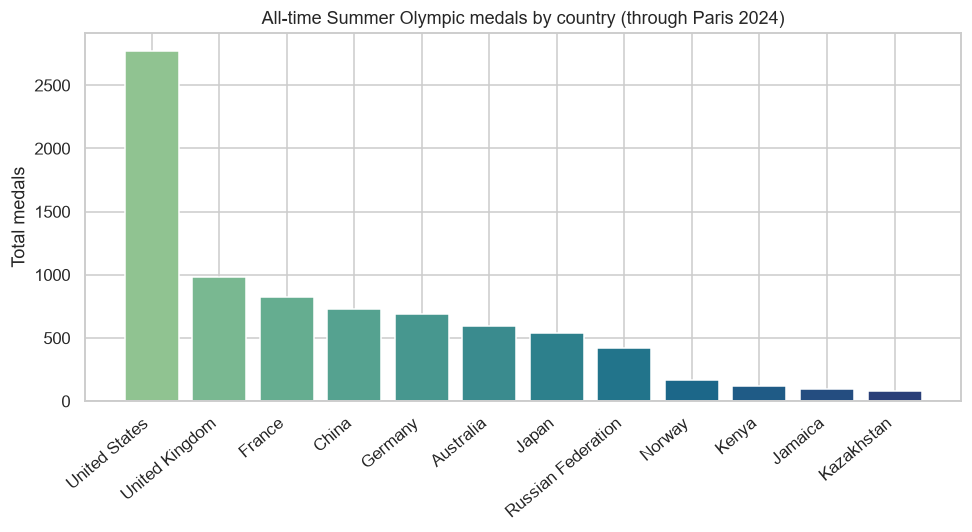

In [37]:
fig, ax = plt.subplots(figsize=(9, 5))
sorted_df = df.sort_values("medals", ascending=False)
ax.bar(sorted_df["country"], sorted_df["medals"],
       color=sns.color_palette("crest", len(sorted_df)))
ax.set_title("All-time Summer Olympic medals by country (through Paris 2024)")
ax.set_ylabel("Total medals")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("fig1_medals_by_country.png")
plt.show()

**Plot 2 - Scatter plot (log-log):** GDP vs. medals, with a linear trend line.

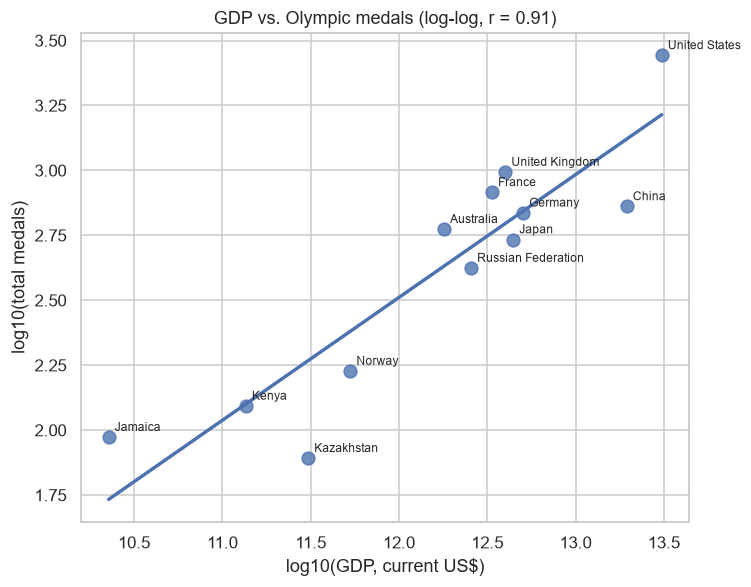

In [38]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.regplot(data=df, x="log_gdp", y="log_medals", ax=ax, ci=None, scatter_kws={"s": 70})
for _, row in df.iterrows():
    ax.annotate(row["country"], (row["log_gdp"], row["log_medals"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title(f"GDP vs. Olympic medals (log-log, r = {r_lgdp:.2f})")
ax.set_xlabel("log10(GDP, current US$)")
ax.set_ylabel("log10(total medals)")
plt.tight_layout()
plt.savefig("fig2_gdp_vs_medals.png")
plt.show()

**Plot 3 - Scatter plot (log-log):** population vs. medals, with a linear trend line.

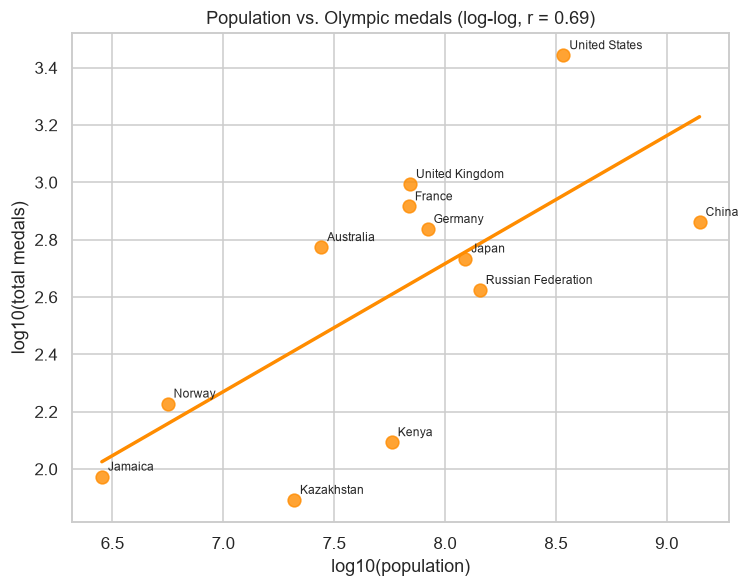

In [39]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.regplot(data=df, x="log_population", y="log_medals", ax=ax, ci=None,
            scatter_kws={"s": 70, "color": "darkorange"}, line_kws={"color": "darkorange"})
for _, row in df.iterrows():
    ax.annotate(row["country"], (row["log_population"], row["log_medals"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title(f"Population vs. Olympic medals (log-log, r = {r_lpop:.2f})")
ax.set_xlabel("log10(population)")
ax.set_ylabel("log10(total medals)")
plt.tight_layout()
plt.savefig("fig3_population_vs_medals.png")
plt.show()

**Plot 4 - "Olympic efficiency":** medals won per $100B of GDP -
which countries overperform their economic size?

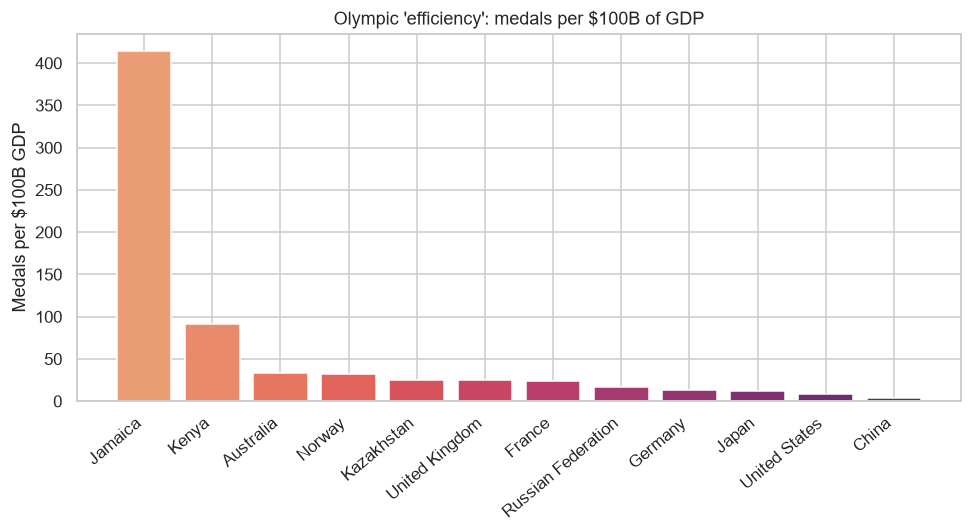

In [40]:
df["medals_per_100b_gdp"] = df["medals"] / (df["gdp_current_usd"] / 1e11)

fig, ax = plt.subplots(figsize=(9, 5))
eff_sorted = df.sort_values("medals_per_100b_gdp", ascending=False)
ax.bar(eff_sorted["country"], eff_sorted["medals_per_100b_gdp"],
       color=sns.color_palette("flare", len(eff_sorted)))
ax.set_title("Olympic 'efficiency': medals per $100B of GDP")
ax.set_ylabel("Medals per $100B GDP")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("fig4_medals_per_gdp.png")
plt.show()